#### Imports


In [1]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit

from tensorflow.keras import layers, models

# Full data loader

In [2]:
dataset_dirs = {
    "phone": Path("har_stage2_production_phones_v1"),
    "watch": Path("har_stage2_production_watch_v1"),
}

class_names = [
    "bike",
    "sit",
    "stairsdown",
    "stairsup",
    "stand",
    "walk"
]

label_to_index = {
    "bike": 0,
    "sit": 1,
    "stairsdown": 2,
    "stairsup": 3,
    "stand": 4,
    "walk": 5
}

all_X = []
all_y = []
all_participants = []
all_sources = []

for source_name, dataset_dir in dataset_dirs.items():
    print(f"\nLoading {source_name}: {dataset_dir}")

    shard_paths = sorted(dataset_dir.glob("windows-*.npz"))
    print("Shards found:", len(shard_paths))

    source_X = []
    source_y = []
    source_participants = []

    for shard_path in shard_paths:
        with np.load(shard_path, allow_pickle=False) as z:
            X = z["X"].astype(np.float32)
            labels = z["labels"]
            metadata = z["metadata"]

            y = np.array([
                label_to_index[str(label)]
                for label in labels
            ], dtype=np.int64)

            participants = np.array([
                json.loads(item)["User"]
                for item in metadata
            ])

        source_X.append(X)
        source_y.append(y)
        source_participants.append(participants)

    X_source = np.concatenate(source_X, axis=0)
    y_source = np.concatenate(source_y, axis=0)
    participants_source = np.concatenate(source_participants, axis=0)

    print("Windows:", X_source.shape[0])
    print("X shape:", X_source.shape)
    print("Participants:", np.unique(participants_source))

    all_X.append(X_source)
    all_y.append(y_source)
    all_participants.append(participants_source)
    all_sources.append(
        np.full(len(X_source), source_name, dtype="<U16")
    )

X = np.concatenate(all_X, axis=0)
y = np.concatenate(all_y, axis=0)
participant_ids = np.concatenate(all_participants, axis=0)
source_ids = np.concatenate(all_sources, axis=0)

print("\nCombined dataset")
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Windows per source:")

for source in np.unique(source_ids):
    print(f"{source}: {np.sum(source_ids == source)}")


Loading phone: har_stage2_production_phones_v1
Shards found: 58
Windows: 32160
X shape: (32160, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Loading watch: har_stage2_production_watch_v1
Shards found: 25
Windows: 5032
X shape: (5032, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Combined dataset
X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Windows per source:
phone: 32160
watch: 5032


In [3]:
assert X.ndim == 3
assert X.shape[1:] == (128, 6)
assert X.dtype == np.float32

assert y.ndim == 1
assert len(y) == len(X)
assert len(participant_ids) == len(X)
assert len(source_ids) == len(X)

assert set(np.unique(y)) == set(range(6))
assert set(np.unique(source_ids)) == {"phone", "watch"}

In [4]:
phone_count = int(np.sum(source_ids == "phone"))
watch_count = int(np.sum(source_ids == "watch"))

print(f"Phone windows: {phone_count}")
print(f"Watch windows: {watch_count}")
print(f"Total windows: {len(X)}")

assert phone_count == 32160, (
    f"Expected 32160 phone windows, got {phone_count}"
)

assert watch_count == 5032, (
    f"Expected 5032 watch windows, got {watch_count}"
)

assert len(X) == 37192, (
    f"Expected 37192 total windows, got {len(X)}"
)

print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Phone windows:", phone_count)
print("Watch windows:", watch_count)

Phone windows: 32160
Watch windows: 5032
Total windows: 37192
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Phone windows: 32160
Watch windows: 5032


In [5]:
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))

print("\nWindows per source:")
for source in np.unique(source_ids):
    print(source, np.sum(source_ids == source))

print("\nWindows per class:")
for index, name in enumerate(class_names):
    print(name, np.sum(y == index))

X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']

Windows per source:
phone 32160
watch 5032

Windows per class:
bike 5494
sit 7330
stairsdown 4784
stairsup 5797
stand 6256
walk 7531


# Split data


In [6]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(X, y, groups=participant_ids)
)

X_train, y_train = X[train_idx], y[train_idx]
X_temp, y_temp = X[temp_idx], y[temp_idx]

# Split the remaining participants into validation and test
temp_participants = np.unique(participant_ids[temp_idx])

rng = np.random.default_rng(42)
rng.shuffle(temp_participants)

n_val = max(1, len(temp_participants) // 2)
val_participants = set(temp_participants[:n_val])
test_participants = set(temp_participants[n_val:])

val_mask = np.isin(participant_ids, list(val_participants))
test_mask = np.isin(participant_ids, list(test_participants))

X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

#### Verify


In [7]:
train_participants = set(np.unique(participant_ids[train_idx]))
val_participants = set(np.unique(participant_ids[val_mask]))
test_participants = set(np.unique(participant_ids[test_mask]))

print("Train participants:", sorted(train_participants))
print("Validation participants:", sorted(val_participants))
print("Test participants:", sorted(test_participants))

print("\nTrain windows:", len(y_train))
print("Validation windows:", len(y_val))
print("Test windows:", len(y_test))

assert train_participants.isdisjoint(val_participants)
assert train_participants.isdisjoint(test_participants)
assert val_participants.isdisjoint(test_participants)

Train participants: [np.str_('a'), np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('i')]
Validation participants: [np.str_('h')]
Test participants: [np.str_('b')]

Train windows: 28581
Validation windows: 4029
Test windows: 4582


In [8]:
for split_name, y_split in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(f"\n{split_name} class counts:")

    for index, name in enumerate(class_names):
        print(f"{name}: {np.sum(y_split == index)}")


Train class counts:
bike: 4040
sit: 5769
stairsdown: 3583
stairsup: 4356
stand: 5086
walk: 5747

Validation class counts:
bike: 518
sit: 852
stairsdown: 661
stairsup: 712
stand: 471
walk: 815

Test class counts:
bike: 936
sit: 709
stairsdown: 540
stairsup: 729
stand: 699
walk: 969


# Normalize

In [9]:
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

# CNN-LSTM model

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = len(class_names)
INPUT_SHAPE = X_train.shape[1:]

model = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    normalizer,

    layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 128, 6)         │            13 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,179 (422.58 KB)

 Trainable params: 107,782 (421.02 KB)

 Non-trainable params: 397 (1.55 KB)

# Train model

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.8819 - loss: 0.3855 - val_accuracy: 0.8861 - val_loss: 0.2813 - learning_rate: 0.0010
Epoch 2/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9552 - loss: 0.1541 - val_accuracy: 0.9037 - val_loss: 0.2882 - learning_rate: 0.0010
Epoch 3/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9639 - loss: 0.1202 - val_accuracy: 0.9027 - val_loss: 0.2404 - learning_rate: 0.0010
Epoch 4/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9734 - loss: 0.0921 - val_accuracy: 0.9057 - val_loss: 0.3188 - learning_rate: 0.0010
Epoch 5/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9747 - loss: 0.0810 - val_accuracy: 0.9191 - val_loss: 0.3097 - learning_rate: 0.0010
Epoch 6/50
446/447 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9784 - loss: 0.0714
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9784 - los

# Test best

In [12]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.6462
Test accuracy: 0.8372


# Predictions and confusion matrix

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

        bike     0.9742    0.9679    0.9711       936
         sit     0.7849    0.3089    0.4433       709
  stairsdown     0.9658    0.8370    0.8968       540
    stairsup     0.8721    0.9726    0.9196       729
       stand     0.5606    0.8798    0.6849       699
        walk     0.9397    0.9649    0.9521       969

    accuracy                         0.8372      4582
   macro avg     0.8496    0.8219    0.8113      4582
weighted avg     0.8573    0.8372    0.8248      4582

[[906  11   1   5  10   3]
 [ 16 219   0   1 472   1]
 [  0   0 452  48   0  40]
 [  0   0   6 709   0  14]
 [  8  49   4  21 615   2]
 [  0   0   5  29   0 935]]


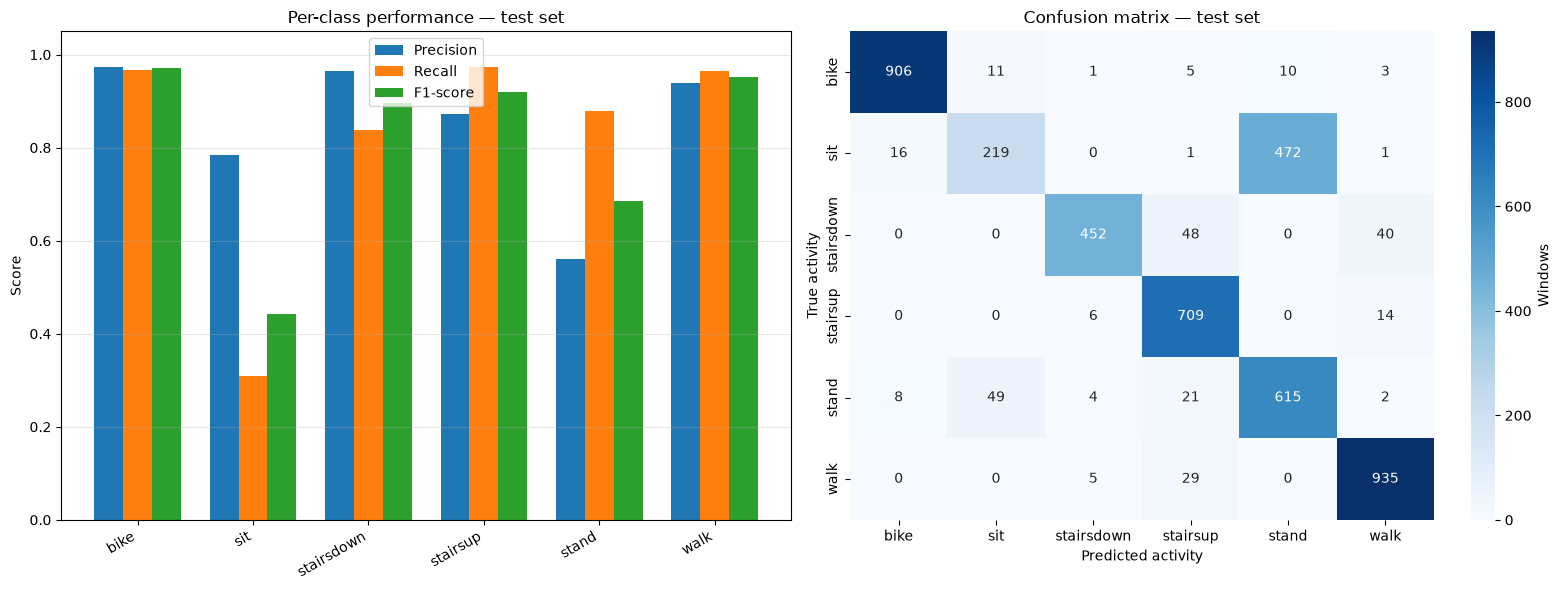

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions from the current trained model
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Compute metrics directly from the current test labels and predictions
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True
)

cm = confusion_matrix(y_test, y_pred)

# Extract per-class metrics in the same order as class_names
precision = [report[name]["precision"] for name in class_names]
recall = [report[name]["recall"] for name in class_names]
f1 = [report[name]["f1-score"] for name in class_names]
support = [report[name]["support"] for name in class_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: precision, recall, and F1-score
x = np.arange(len(class_names))
width = 0.25

axes[0].bar(x - width, precision, width, label="Precision")
axes[0].bar(x, recall, width, label="Recall")
axes[0].bar(x + width, f1, width, label="F1-score")

axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, rotation=30, ha="right")
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Score")
axes[0].set_title("Per-class performance — test set")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Right: confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Windows"},
    ax=axes[1]
)

axes[1].set_xlabel("Predicted activity")
axes[1].set_ylabel("True activity")
axes[1].set_title("Confusion matrix — test set")

plt.tight_layout()
plt.show()

Whats up world!